In [74]:
import csv 
import numpy as np 
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

In [75]:
# def write_data_to_csv(self, filename):
#     headings = ['time', 'strain energy'] + [f'charge_{i}_x' for i in range(self.num_charges)] + [f'charge_{i}_y' for i in range(self.num_charges)]
#     assert len(self.t_log) == len(self.energy_log) == len(self.charged_nodes_positions_log), "Logs must have the same length"
#     num_logs = len(self.t_log)
#     with open(filename, mode='w', newline='') as file:
#         writer = csv.writer(file)
#         writer.writerow(headings)
#         for i in range(num_logs):
#             row = [self.t_log[i], self.energy_log[i]]
#             charged_positions = self.charged_nodes_positions_log[i]
#             for pos in charged_positions:
#                 row.extend(pos)
#             writer.writerow(row)

def read_data_from_csv(filename):
    t_log = []
    energy_log = []
    charged_nodes_positions_log = []
    with open(filename, mode='r') as file:
        reader = csv.reader(file)
        headings = next(reader)  # Skip the header row
        for row in reader:
            t_log.append(float(row[0]))
            energy_log.append(float(row[1]))
            num_charges = (len(row) - 2) // 2
            charged_positions = []
            for i in range(num_charges):
                x = float(row[2 + 2*i])
                y = float(row[3 + 2*i])
                charged_positions.append((x, y))
            charged_nodes_positions_log.append(charged_positions)
    return t_log, energy_log, charged_nodes_positions_log

Time of maximum energy minimum: 23.0, Energy at that time: 0.012901235614040848
Times of energy maxima: [14.], Energies at those times: [2.99174447]


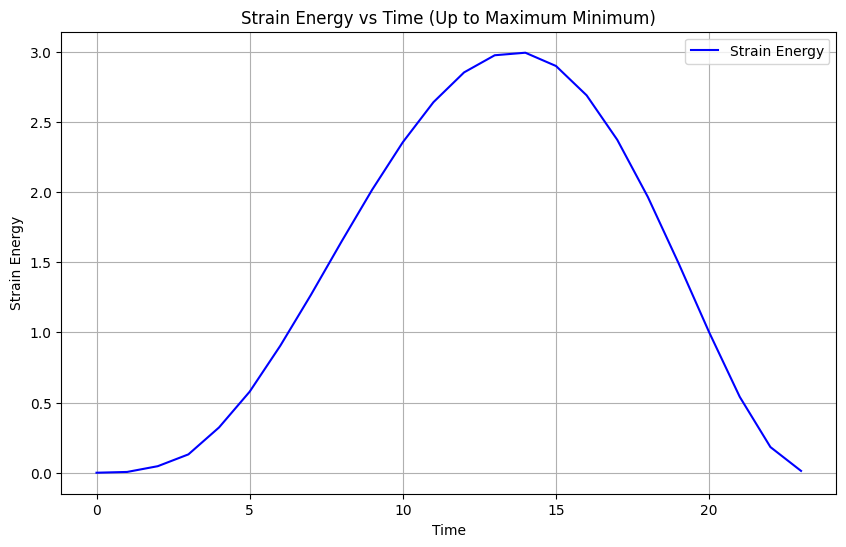

In [106]:
t_log, energy_log, charged_nodes_positions_log = read_data_from_csv("simulation_data.csv")
t_log = np.array(t_log)
energy_log = np.array(energy_log)


minima_indices, _ = find_peaks([-e for e in energy_log])
max_idx = minima_indices[np.argmax(t_log[minima_indices])]
print(f"Time of maximum energy minimum: {t_log[max_idx]}, Energy at that time: {energy_log[max_idx]}")
t_log_filtered = t_log[:max_idx+1]
energy_log_filtered = energy_log[:max_idx+1]

maxima_indices, _ = find_peaks(energy_log_filtered)
print(f"Times of energy maxima: {t_log_filtered[maxima_indices]}, Energies at those times: {energy_log_filtered[maxima_indices]}")

plt.figure(figsize=(10, 6))
plt.plot(t_log_filtered, energy_log_filtered, label='Strain Energy', color='blue')
plt.title('Strain Energy vs Time (Up to Maximum Minimum)')
plt.xlabel('Time')
plt.ylabel('Strain Energy')
plt.grid()
plt.legend()
plt.show()

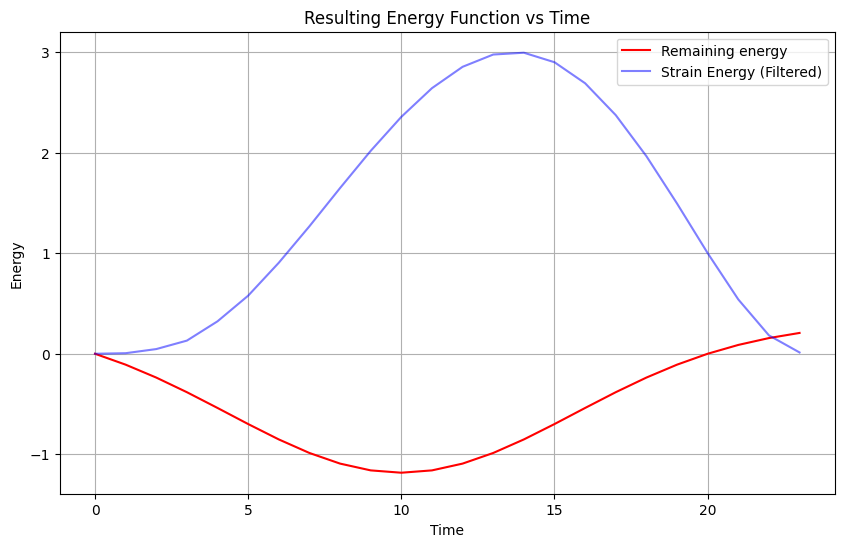

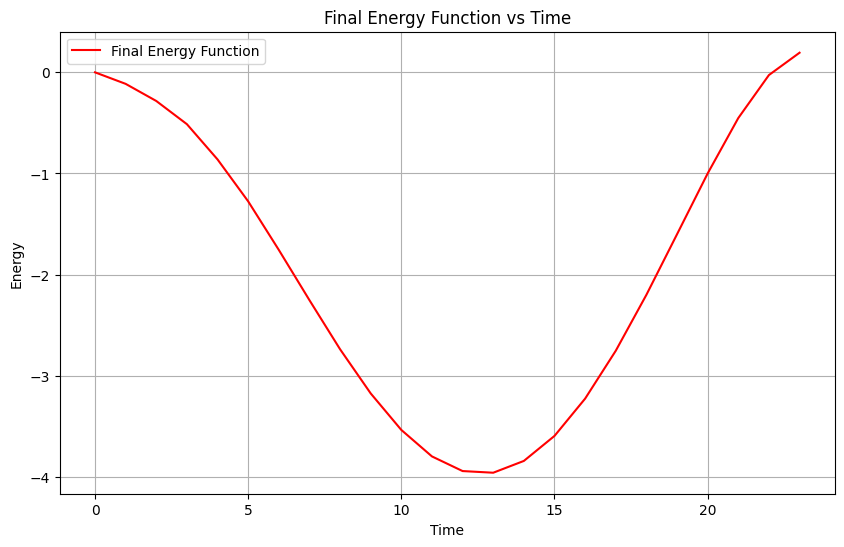

In [133]:
α = int((max_idx)*1.1)
β = int(maxima_indices[0]*0.7)
σ = 0.5*np.abs(α-β)
# print(f"α : {t_log[α]}, β : {t_log[β]}")
# a = (β/(α-β))*np.exp((-1/(2*σ*σ))*(2*β*α - α*α))
a = np.max(energy_log_filtered) * 0.5

def gaussian(t, μ, σ, a):
    return a * np.exp(-((t - μ) / σ) ** 2)



def resulting_energy_function_non_interacting(t, β, σ, a):
    val =  -gaussian(t, μ=β, σ=σ, a=a) + gaussian(0, μ=β, σ=σ, a=a)
    return val

# Plotting the final energy function
# t_values = np.linspace(0, t_log_filtered[-1], 1000)
final_energy_values = resulting_energy_function_non_interacting(t_log_filtered, β=β, σ=σ, a=a)
plt.figure(figsize=(10, 6))
plt.plot(t_log_filtered, final_energy_values, label='Remaining energy', color='red')
plt.plot(t_log_filtered, energy_log_filtered, label='Strain Energy (Filtered)', color='blue', alpha=0.5)
plt.title('Resulting Energy Function vs Time')
plt.xlabel('Time')
plt.ylabel('Energy')
plt.grid()
plt.legend()
plt.show()

#Plot the sum of the two functions
plt.figure(figsize=(10, 6))
plt.plot(t_log_filtered, final_energy_values - energy_log_filtered, label='Final Energy Function', color='red')
# plt.plot(t_log_filtered, energy_log_filtered, label='Strain Energy (Filtered)', color='blue', alpha=0.5)
plt.title('Final Energy Function vs Time')
plt.xlabel('Time')
plt.ylabel('Energy')
plt.grid()
plt.legend()
plt.show()
    

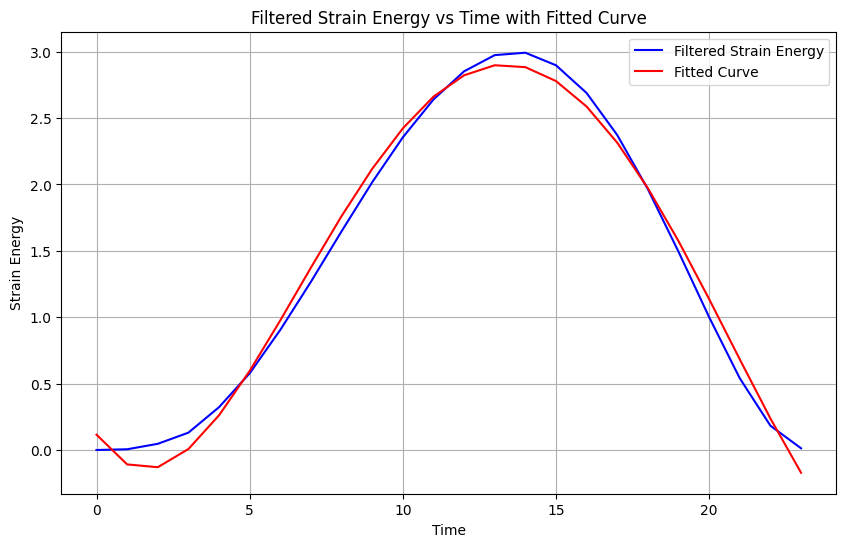

In [103]:
# Plot the filtered energy curve and the fit new curve throught it
coefficients_filtered = np.polyfit(t_log_filtered, energy_log_filtered, deg=4)
energy_poly_filtered = np.poly1d(coefficients_filtered)
energy_fit_filtered =  energy_poly_filtered(t_log_filtered)
plt.figure(figsize=(10, 6))
plt.plot(t_log_filtered, energy_log_filtered, label='Filtered Strain Energy', color='blue')
plt.plot(t_log_filtered, energy_fit_filtered, label='Fitted Curve', color='red')
plt.title('Filtered Strain Energy vs Time with Fitted Curve')
plt.xlabel('Time')
plt.ylabel('Strain Energy')
plt.grid()
plt.legend()
plt.show()